In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

%matplotlib inline
print("Library berhasil diimpor.")

Library berhasil diimpor.


In [5]:
from pathlib import Path

file_path = Path("coffee_shop.csv")

if file_path.exists():
    df = pd.read_csv(file_path)
    print("Dataset asli berhasil dibaca:", file_path)
else:
    data = {
        "Tanggal": pd.date_range("2025-01-01", periods=30, freq="D"),
        "Produk": [
            "Kopi Hitam", "Cappuccino", "Latte", "Americano", "Mocha"
        ] * 6,
        "Jumlah_Terjual": [
            20, 15, 18, 12, 10,
            22, 17, 19, 14, 11,
            25, 18, 21, 15, 13,
            23, 16, 20, 13, 12,
            28, 20, 24, 17, 15,
            26, 19, 22, 16, 14
        ],
        "Harga": [
            10000, 18000, 20000, 15000, 22000
        ] * 6
    }
    df = pd.DataFrame(data)
    print("File coffee_shop.csv tidak ditemukan. Menggunakan data contoh sintetis.")

df["Tanggal"] = pd.to_datetime(df["Tanggal"], errors="coerce")
df["Pendapatan"] = df["Jumlah_Terjual"] * df["Harga"]
display(df.head())

File coffee_shop.csv tidak ditemukan. Menggunakan data contoh sintetis.


,Tanggal,Produk,Jumlah_Terjual,Harga,Pendapatan
0,2025-01-01,Kopi Hitam,20,10000,200000
1,2025-01-02,Cappuccino,15,18000,270000
2,2025-01-03,Latte,18,20000,360000
3,2025-01-04,Americano,12,15000,180000
4,2025-01-05,Mocha,10,22000,220000


In [6]:
print("Jumlah baris dan kolom:", df.shape)
print("\nInformasi dataset:")
df.info()

print("\nStatistik deskriptif:")
display(df.describe(include="all"))

Jumlah baris dan kolom: (30, 5)

Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Tanggal         30 non-null     datetime64[us]
 1   Produk          30 non-null     str           
 2   Jumlah_Terjual  30 non-null     int64         
 3   Harga           30 non-null     int64         
 4   Pendapatan      30 non-null     int64         
dtypes: datetime64[us](1), int64(3), str(1)
memory usage: 1.3 KB

Statistik deskriptif:


,Tanggal,Produk,Jumlah_Terjual,Harga,Pendapatan
count,30,30,30.000000,30.000000,30.000000
unique,NaN,5,NaN,NaN,NaN
top,NaN,Kopi Hitam,NaN,NaN,NaN
freq,NaN,6,NaN,NaN,NaN
mean,2025-01-15 12:00:00,NaN,17.833333,17000.000000,292166.666667
min,2025-01-01 00:00:00,NaN,10.000000,10000.000000,180000.000000
25%,2025-01-08 06:00:00,NaN,14.250000,15000.000000,232500.000000
50%,2025-01-15 12:00:00,NaN,17.500000,18000.000000,275000.000000
75%,2025-01-22 18:00:00,NaN,20.750000,20000.000000,339000.000000
max,2025-01-30 00:00:00,NaN,28.000000,22000.000000,480000.000000


In [9]:
missing_values = df.isnull().sum()
missing_percentage = (missing_values / len(df)) * 100

missing_data = pd.DataFrame({
    "Jumlah Missing Value": missing_values,
    "Persentase (%)": missing_percentage
})

display(missing_data[missing_data["Jumlah Missing Value"] > 0])

# Isi missing value numerik dengan median dan kategorikal dengan modus
for col in df.select_dtypes(include=["number"]).columns:
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include=["object", "string"]).columns:
    if df[col].isnull().any() and not df[col].mode().empty:
        df[col] = df[col].fillna(df[col].mode()[0])

print("Pemeriksaan missing value setelah penanganan:")
display(df.isnull().sum())

,Jumlah Missing Value,Persentase (%)


Pemeriksaan missing value setelah penanganan:


Tanggal           0
Produk            0
Jumlah_Terjual    0
Harga             0
Pendapatan        0
dtype: int64

In [10]:
print("Jumlah baris duplikat:", df.duplicated().sum())
df = df.drop_duplicates().copy()
print("Ukuran dataset setelah duplikat dihapus:", df.shape)

Jumlah baris duplikat: 0
Ukuran dataset setelah duplikat dihapus: (30, 5)


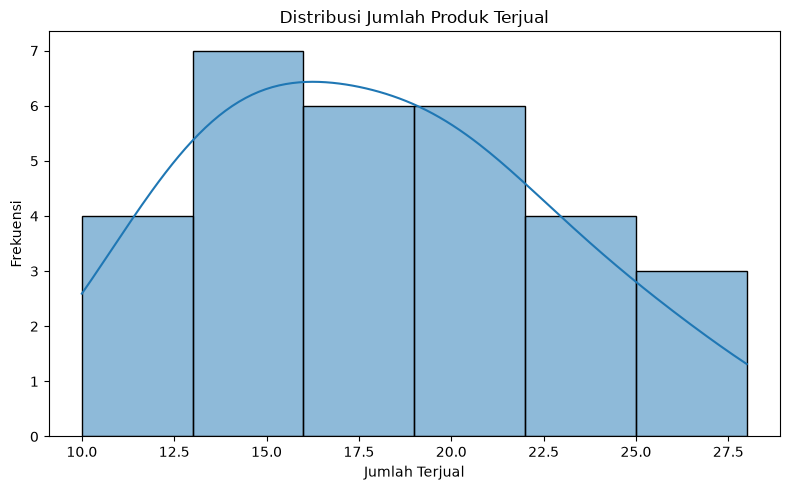

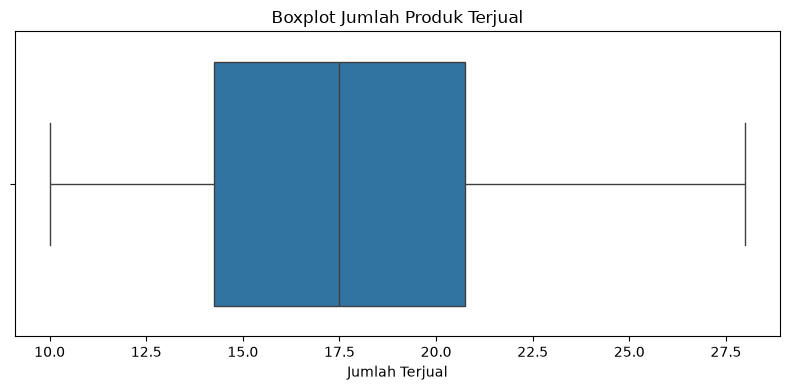

In [11]:
# Histogram jumlah penjualan
plt.figure(figsize=(8, 5))
sns.histplot(df["Jumlah_Terjual"], kde=True)
plt.title("Distribusi Jumlah Produk Terjual")
plt.xlabel("Jumlah Terjual")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

# Boxplot untuk memeriksa outlier
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["Jumlah_Terjual"])
plt.title("Boxplot Jumlah Produk Terjual")
plt.xlabel("Jumlah Terjual")
plt.tight_layout()
plt.show()

,Total_Terjual,Total_Pendapatan
Produk,,
Kopi Hitam,144,1440000
Latte,124,2480000
Cappuccino,105,1890000
Americano,87,1305000
Mocha,75,1650000


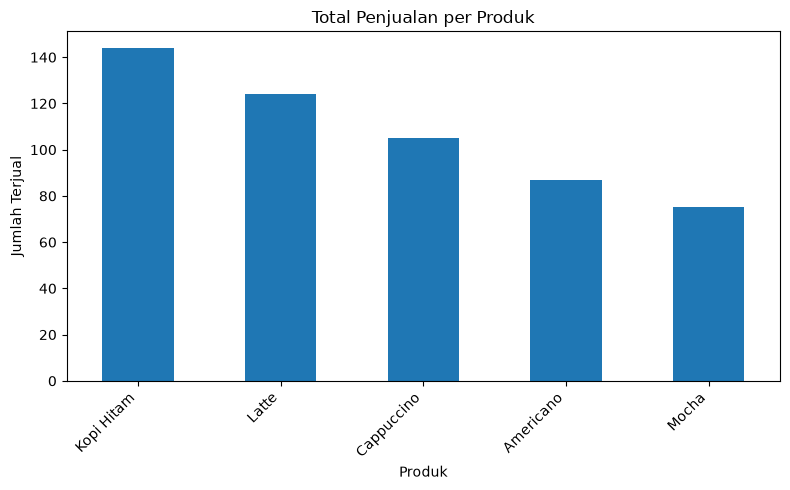

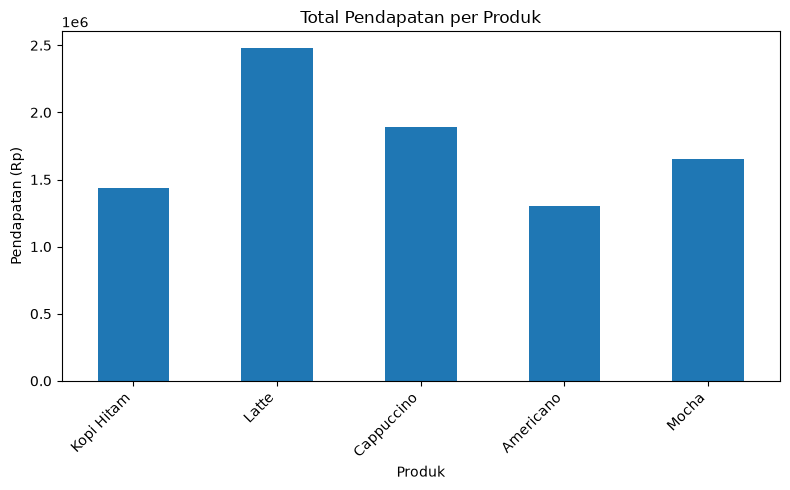

In [12]:
ringkasan_produk = df.groupby("Produk").agg(
    Total_Terjual=("Jumlah_Terjual", "sum"),
    Total_Pendapatan=("Pendapatan", "sum")
).sort_values("Total_Terjual", ascending=False)

display(ringkasan_produk)

ringkasan_produk["Total_Terjual"].plot(kind="bar", figsize=(8, 5))
plt.title("Total Penjualan per Produk")
plt.xlabel("Produk")
plt.ylabel("Jumlah Terjual")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

ringkasan_produk["Total_Pendapatan"].plot(kind="bar", figsize=(8, 5))
plt.title("Total Pendapatan per Produk")
plt.xlabel("Produk")
plt.ylabel("Pendapatan (Rp)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [13]:
df["Hari"] = df["Tanggal"].dt.day
df["Bulan"] = df["Tanggal"].dt.month
df["Hari_Minggu"] = df["Tanggal"].dt.dayofweek

# One-hot encoding untuk kolom Produk
df_encoded = pd.get_dummies(
    df,
    columns=["Produk"],
    dtype=int
)

display(df_encoded.head())

,Tanggal,Jumlah_Terjual,Harga,Pendapatan,Hari,Bulan,Hari_Minggu,Produk_Americano,Produk_Cappuccino,Produk_Kopi Hitam,Produk_Latte,Produk_Mocha
0,2025-01-01,20,10000,200000,1,1,2,0,0,1,0,0
1,2025-01-02,15,18000,270000,2,1,3,0,1,0,0,0
2,2025-01-03,18,20000,360000,3,1,4,0,0,0,1,0
3,2025-01-04,12,15000,180000,4,1,5,1,0,0,0,0
4,2025-01-05,10,22000,220000,5,1,6,0,0,0,0,1


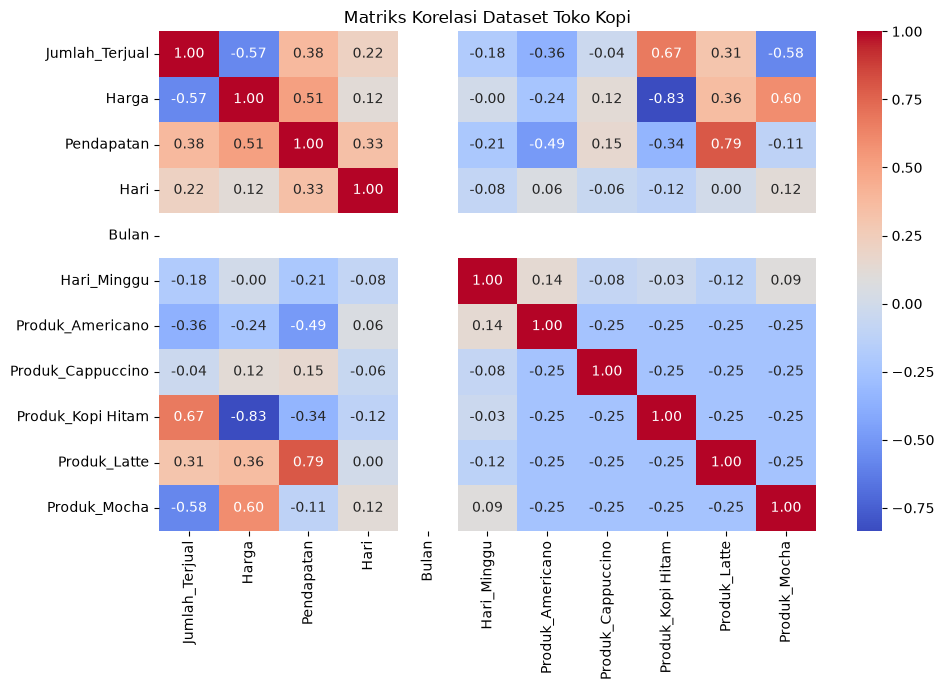

In [14]:
numeric_df = df_encoded.select_dtypes(include=["number"])

plt.figure(figsize=(10, 7))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matriks Korelasi Dataset Toko Kopi")
plt.tight_layout()
plt.show()

In [15]:
# Target adalah jumlah produk terjual.
# Kolom pendapatan tidak digunakan sebagai fitur karena dihitung dari jumlah terjual x harga.
target = "Jumlah_Terjual"

feature_columns = [
    col for col in df_encoded.select_dtypes(include=["number"]).columns
    if col not in ["Jumlah_Terjual", "Pendapatan"]
]

X = df_encoded[feature_columns]
y = df_encoded[target]

print("Fitur yang digunakan:")
print(X.columns.tolist())
print("\nJumlah data:", len(X))

Fitur yang digunakan:
['Harga', 'Hari', 'Bulan', 'Hari_Minggu', 'Produk_Americano', 'Produk_Cappuccino', 'Produk_Kopi Hitam', 'Produk_Latte', 'Produk_Mocha']

Jumlah data: 30


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

Jumlah data training: 24
Jumlah data testing: 6


In [17]:
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)
prediksi = model.predict(X_test)

hasil = pd.DataFrame({
    "Aktual": y_test.to_numpy(),
    "Prediksi": np.round(prediksi, 2)
})

display(hasil)

,Aktual,Prediksi
0,22,21.29
1,23,25.67
2,17,15.37
3,20,20.28
4,14,14.07
5,11,12.91


In [18]:
mae = mean_absolute_error(y_test, prediksi)
rmse = np.sqrt(mean_squared_error(y_test, prediksi))
r2 = r2_score(y_test, prediksi) if len(y_test) > 1 else float("nan")

print("Evaluasi Model Random Forest Regressor")
print("MAE  :", round(mae, 2))
print("RMSE :", round(rmse, 2))
print("R²   :", round(r2, 3))

Evaluasi Model Random Forest Regressor
MAE  : 1.21
RMSE : 1.53
R²   : 0.873


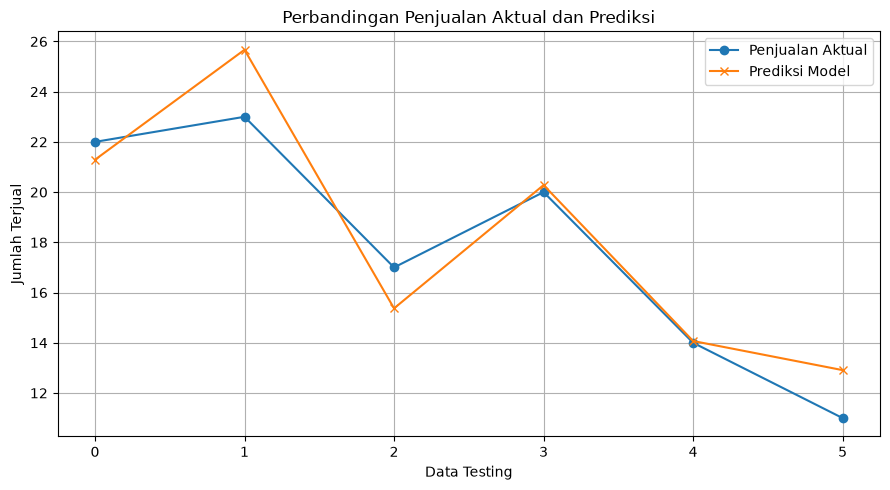

In [19]:
plt.figure(figsize=(9, 5))
plt.plot(y_test.to_numpy(), marker="o", label="Penjualan Aktual")
plt.plot(prediksi, marker="x", label="Prediksi Model")
plt.title("Perbandingan Penjualan Aktual dan Prediksi")
plt.xlabel("Data Testing")
plt.ylabel("Jumlah Terjual")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [20]:
produk_terlaris = df.groupby("Produk")["Jumlah_Terjual"].sum().idxmax()
total_terjual = df["Jumlah_Terjual"].sum()
total_pendapatan = df["Pendapatan"].sum()

print("KESIMPULAN MACHINE LEARNING TOKO KOPI")
print("======================================")
print(f"Jumlah seluruh produk terjual: {total_terjual} gelas")
print(f"Total pendapatan: Rp{total_pendapatan:,.0f}")
print(f"Produk dengan jumlah penjualan tertinggi: {produk_terlaris}")
print("Algoritma yang digunakan: Random Forest Regressor")
print(f"MAE model: {mae:.2f}")
print(f"RMSE model: {rmse:.2f}")
print(f"R² model: {r2:.3f}")
print("\nCatatan: hasil di atas berasal dari dataset yang dimuat.")
print("Jika menggunakan data contoh sintetis, hasil tidak mewakili toko kopi nyata.")

KESIMPULAN MACHINE LEARNING TOKO KOPI
Jumlah seluruh produk terjual: 535 gelas
Total pendapatan: Rp8,765,000
Produk dengan jumlah penjualan tertinggi: Kopi Hitam
Algoritma yang digunakan: Random Forest Regressor
MAE model: 1.21
RMSE model: 1.53
R² model: 0.873

Catatan: hasil di atas berasal dari dataset yang dimuat.
Jika menggunakan data contoh sintetis, hasil tidak mewakili toko kopi nyata.
